In [4]:
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
from torchinfo import summary
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'

In [5]:
df = pd.read_csv('riceClassification.csv')
df.head()

,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,1,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,4,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,5,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


# Here we have removed all the rows where missing values are present and also deleted the 'id' column.

In [6]:
df.dropna(inplace= True)
df.drop(['id'], axis = 1, inplace= True)
print(df.shape)

(18185, 11)


In [7]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


In [8]:
print(df['Class'].unique())
print(df['Class'].value_counts())

[1 0]
Class
1    9985
0    8200
Name: count, dtype: int64


In [9]:
odf = df.copy()

for col in df.columns:
    df[col] = df[col] / df[col].abs().max()

df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,0.444368,0.503404,0.775435,0.744658,0.424873,0.666610,0.741661,0.537029,0.844997,0.368316,1.0
1,0.281293,0.407681,0.622653,0.750489,0.273892,0.530370,0.804230,0.409661,0.919215,0.371471,1.0
2,0.298531,0.416421,0.630442,0.756341,0.284520,0.546380,0.856278,0.412994,0.959862,0.374747,1.0
3,0.300979,0.420463,0.629049,0.764024,0.286791,0.548616,0.883772,0.414262,0.961818,0.379222,1.0
4,0.361704,0.464626,0.682901,0.775033,0.345385,0.601418,0.867808,0.452954,0.966836,0.386007,1.0


In [10]:
X = np.array(df.iloc[:, :-1])
Y = np.array(df.iloc[:,-1])

Here we have given 70% for training and 30% for Testing

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = 0.3)

Here the testing data is split into half i.e 30%/2 => 15% for validation and 15% Testing.

In [12]:
X_test, X_val, y_test, y_val = train_test_split(X_test, y_test, test_size = 0.5)

Here we can see that the train has got 70% of the data testing has got 15% and validation got 15%.

In [13]:
print(X_train.shape)
print(X_test.shape)
print(X_val.shape)

(12729, 10)
(2728, 10)
(2728, 10)


torch.tensor() is used to convert the I/P data(eg: List, tuple, float, etc) into tensor so pytorch can understand the data.

The code represents the accessibility of the data about how we can access all the data in the dataset

In [14]:
class ds(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32).to(device)
        self.Y = torch.tensor(Y, dtype=torch.float32).to(device)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.Y[index]

Here we have created the dataset object till now.

In [15]:
training_data = ds(X_train, y_train)
testing_data = ds(X_test, y_test)
validation_data = ds(X_val, y_val)

# Data Loader Concept
In this we send a batch of data to the ML model so as to train data and get the outputs.

In [16]:
train_dataloader = DataLoader(training_data, batch_size= 32, shuffle= True) # When we shuffle the data it helps in avoiding Bias in the output.
test_dataloader = DataLoader(testing_data, batch_size= 32, shuffle= True)
validation_dataloader = DataLoader(validation_data, batch_size= 32, shuffle= True)

In [17]:
Hidden_Nurons = 10
class my_modal(nn.Module):
    def __init__(self,):
        super(my_modal, self).__init__()
        self.input_layer = nn.Linear(X.shape[1], Hidden_Nurons)
        self.linear = nn.Linear(Hidden_Nurons, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.input_layer(x) # The output of the I/P layer will go to the x variable
        x = self.linear(x) # Then then the value stored in the x will go through the linear function
        x = self.sigmoid(x) # the output of the linear function that is stored in the var x will be processed for the signmoid function
        return x

modal = my_modal().to(device)

In [18]:
summary(modal, input_size=(1, X.shape[1]), device=device)

Layer (type:depth-idx)                   Output Shape              Param #
my_modal                                 [1, 1]                    --
├─Linear: 1-1                            [1, 10]                   110
├─Linear: 1-2                            [1, 1]                    11
├─Sigmoid: 1-3                           [1, 1]                    --
Total params: 121
Trainable params: 121
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

# Loss and the Optimizer

In [19]:
criterion = nn.BCELoss() # Binary Class Entropy Loss (BCELoss)
optimizer = Adam(modal.parameters(), lr= 1e-3)

# Training Function

In [20]:
total_loss_train_plot = []
total_loss_validation_plot = []
total_acc_train_plot = []
total_acc_validation_plot = []

epochs = 10
for epoch in range (epochs):
    total_acc_train = 0
    total_loss_train = 0
    total_acc_val = 0
    total_loss_val = 0

    for data in train_dataloader:
        inputs, lables = data # I/P = 8 rows, lables = 8 Lables

        prediction = modal(inputs).squeeze(1) # Squeeze is used to change the shape of the data so that we can convert it into a 1D array so that training can be carried on

        batch_loss = criterion(prediction, lables)

        total_loss_train += batch_loss.item()

        acc = ((prediction).round() == lables).sum().item() # Till here we have done the forward propogation

        total_acc_train += acc

        batch_loss.backward()
        optimizer.step()
        optimizer.zero_grad() # After processing of a batch the optimizer restarts from 0 for the next epoch

# Validation Step
    with torch.no_grad():
        for data in validation_dataloader:
            inputs, lables = data

            prediction = modal(inputs).squeeze(1)

            batch_loss = criterion(prediction, lables)

            total_loss_val += batch_loss.item()
            
            acc = ((prediction).round() == lables).sum().item()
            
            total_acc_val += acc

    total_loss_train_plot.append(round(total_loss_train/1000 , 4))
    total_loss_validation_plot.append(round(total_loss_val/1000 , 4))
    
    total_acc_train_plot.append(round(total_acc_train/training_data.__len__() * 100 , 4)) # Here we need the % so we have written the formula 
    total_acc_validation_plot.append(round(total_acc_val/validation_data.__len__() * 100 , 4))

    print(f'Epochs: {epoch + 1}, Train Loss: {round(total_loss_train/1000 , 4)}, Train Accuracy: {round(total_acc_train/training_data.__len__() * 100 , 4)}, Validation Loss: {round(total_loss_val/1000 , 4)}, Validation Accuracy: {round(total_acc_val/validation_data.__len__() * 100 , 4)}')

    print("=" * 50)

Epochs: 1, Train Loss: 0.2437, Train Accuracy: 78.9143, Validation Loss: 0.039, Validation Accuracy: 97.6906
Epochs: 2, Train Loss: 0.117, Train Accuracy: 98.1852, Validation Loss: 0.0158, Validation Accuracy: 98.4971
Epochs: 3, Train Loss: 0.0534, Train Accuracy: 98.4288, Validation Loss: 0.009, Validation Accuracy: 98.4971
Epochs: 4, Train Loss: 0.0342, Train Accuracy: 98.5073, Validation Loss: 0.0066, Validation Accuracy: 98.5337
Epochs: 5, Train Loss: 0.0265, Train Accuracy: 98.5781, Validation Loss: 0.0058, Validation Accuracy: 98.3504
Epochs: 6, Train Loss: 0.0225, Train Accuracy: 98.633, Validation Loss: 0.0049, Validation Accuracy: 98.5337
Epochs: 7, Train Loss: 0.0202, Train Accuracy: 98.6645, Validation Loss: 0.0047, Validation Accuracy: 98.5337
Epochs: 8, Train Loss: 0.0188, Train Accuracy: 98.6802, Validation Loss: 0.0043, Validation Accuracy: 98.4971
Epochs: 9, Train Loss: 0.0178, Train Accuracy: 98.6802, Validation Loss: 0.0042, Validation Accuracy: 98.5337
Epochs: 10, Tr

# Testing Modal

In [21]:
with torch.no_grad():
    total_loss_test = 0
    total_acc_test = 0
    for data in test_dataloader:
        inputs, lables = data

        prediction = modal(inputs).squeeze(1) # Squeeze is used to change the shape of the data so that we can convert it into a 1D array so that training can be carried on
        
        batch_loss = criterion(prediction, lables)
        
        total_loss_test += batch_loss.item()
        
        acc = ((prediction).round() == lables).sum().item()

        total_acc_test += acc

print(f'Accuracy: {round(total_acc_test/testing_data.__len__() * 100 , 4)}')

Accuracy: 98.4971


# Visualisation

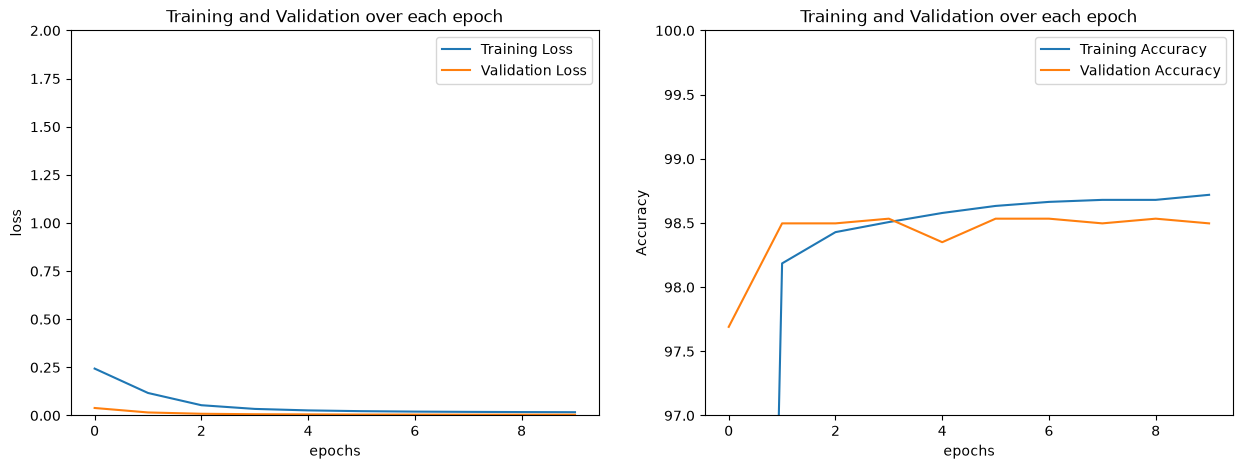

In [22]:
fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize = (15,5))

axs[0].plot(total_loss_train_plot, label = 'Training Loss')
axs[0].plot(total_loss_validation_plot, label = 'Validation Loss')
axs[0].set_title("Training and Validation over each epoch")
axs[0].set_xlabel('epochs')
axs[0].set_ylabel('loss')
axs[0].set_ylim([0,2])
axs[0].legend()

axs[1].plot(total_acc_train_plot, label = 'Training Accuracy')
axs[1].plot(total_acc_validation_plot, label = 'Validation Accuracy')
axs[1].set_title("Training and Validation over each epoch")
axs[1].set_xlabel('epochs')
axs[1].set_ylabel('Accuracy')
axs[1].set_ylim([97,100])
axs[1].legend()

plt.show()

# Prediction Result

In [23]:
area = 3425/odf['Area'].abs().max()

MajorAxisLength = 67/odf['MajorAxisLength'].abs().max()

MinorAxisLength = 72/odf['MinorAxisLength'].abs().max()

Eccentricity = 42/odf['Eccentricity'].abs().max()

ConvexArea = 6767/odf['ConvexArea'].abs().max()

EquivDiameter = 21/odf['EquivDiameter'].abs().max()

Extent = 89/odf['Extent'].abs().max()

Perimeter = 250/odf['Perimeter'].abs().max()

Roundness = 0.50/odf['Roundness'].abs().max()

AspectRation = 123/odf['AspectRation'].abs().max()

pred = modal(torch.tensor([area, MajorAxisLength, MinorAxisLength, Eccentricity,ConvexArea, EquivDiameter, Extent, Perimeter, Roundness,AspectRation], dtype= torch.float32).to(device))

In [24]:
odf.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


In [25]:
pred

tensor([1.], device='mps:0', grad_fn=<SigmoidBackward0>)

In [26]:
pred.item() # The predicted O/P is 1 i.e Jasmine

1.0